# Data Understanding & Exploratory Data Analysis (EDA)
## Comprehensive Audit of Supply Chain Transactions, Schema Dictionary & Web Logs

### Project Phase 1 Scope & Architecture:
This notebook is strictly focused on **Data Understanding and Exploratory Data Analysis (EDA)**. **No columns or records are removed or altered in this phase.** The raw data is audited, inspected, and profiled in its complete, original form across all 53 columns to uncover patterns, anomalies, distributions, and cross-dataset relationships.

#### Key Exploration Modules:
1. **Data Ingestion & Verification:** Multi-encoding loading (`cp1252` for Supply Chain, `utf-8` for Dictionary and Access Logs).
2. **Data Grain & Structural Understanding:** Transaction granularity (`Order Item` vs `Order`), dimensions, memory footprint, and data dictionary schema alignment.
3. **Data Quality & Integrity Diagnostics:** Missing values, custom placeholder detection, duplicate row auditing, and 100% redundant/collinear column identification.
4. **Mathematical & Business Consistency:** Arithmetic verification (`Sales = Price * Qty`, `Total = Sales - Discount`), negative loss distributions, and range sanity checks.
5. **Geographical & Categorical Distributions:** Spatial patterns, zipcode shift diagnostic, country-level missingness, and core operational dimensions.
6. **Numerical Distributions & Outlier Analytics:** Descriptive statistics, skewness, IQR outlier detection, histograms, KDE curves, and boxplots.
7. **Operational Dynamics & Target Leakage Investigation:** Deterministic leakage in `Delivery Status` vs `Late_delivery_risk`, and correlation matrix.
8. **Web Traffic Analytics & Cross-Dataset Synergy:** 24-hour request curves, crawler/bot identification, and browsing-to-sales conversion funnel.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings

warnings.filterwarnings('ignore')

# Display configurations
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# Styling and visualization theme
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

print("Environment configured successfully. Ready for pure Data Understanding & EDA.")

Environment configured successfully. Ready for pure Data Understanding & EDA.


## 1. Data Ingestion & Overview of Original Datasets

In [2]:
# Ingest all datasets with validated encodings (No data removal applied)
a = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="cp1252")
b = pd.read_csv("DescriptionDataCoSupplyChain.csv", encoding="utf-8")
c = pd.read_csv("tokenized_access_logs.csv", encoding="utf-8")

print(f"Dataset a (Supply Chain Transactions): {a.shape[0]:,} rows x {a.shape[1]} columns")
print(f"Dataset b (Data Dictionary):           {b.shape[0]:,} rows x {b.shape[1]} columns")
print(f"Dataset c (Web Access Logs):           {c.shape[0]:,} rows x {c.shape[1]} columns")

memory_a = a.memory_usage(deep=True).sum() / (1024 * 1024)
memory_c = c.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"\nMemory Footprint - Dataset a: {memory_a:.2f} MB | Dataset c: {memory_c:.2f} MB")

Dataset a (Supply Chain Transactions): 180,519 rows x 53 columns
Dataset b (Data Dictionary):           52 rows x 2 columns
Dataset c (Web Access Logs):           469,977 rows x 8 columns

Memory Footprint - Dataset a: 128.28 MB | Dataset c: 114.88 MB


## 2. Analytical Grain & Primary Key Verification

In [3]:
# Establish the transaction grain
total_rows = len(a)
unique_orders = a['Order Id'].nunique()
unique_items = a['Order Item Id'].nunique()
unique_customers = a['Customer Id'].nunique()
unique_products = a['Product Card Id'].nunique()

print("=== Analytical Grain Verification ===")
print(f"Total Transaction Rows:                  {total_rows:,}")
print(f"Unique Order Identifiers (Order Id):     {unique_orders:,}")
print(f"Unique Item Identifiers (Order Item Id):  {unique_items:,}")
print(f"Unique Customer Identifiers:             {unique_customers:,}")
print(f"Unique Product Identifiers:              {unique_products:,}")
print(f"\nIs 'Order Item Id' a 100% Unique Primary Key? {unique_items == total_rows}")
print(f"Average Items per Order: {total_rows / unique_orders:.2f} items (Min: {a['Order Id'].value_counts().min()}, Max: {a['Order Id'].value_counts().max()})")
print("Conclusion: The grain of this dataset is strictly at the individual order item level.")

=== Analytical Grain Verification ===
Total Transaction Rows:                  180,519
Unique Order Identifiers (Order Id):     65,752
Unique Item Identifiers (Order Item Id):  180,519
Unique Customer Identifiers:             20,652
Unique Product Identifiers:              118

Is 'Order Item Id' a 100% Unique Primary Key? True
Average Items per Order: 2.75 items (Min: 1, Max: 5)
Conclusion: The grain of this dataset is strictly at the individual order item level.


In [4]:
# Comprehensive 53-Column Profile Table (Types, Missing %, Cardinality, Samples)
profile_list = []
for col in a.columns:
    series = a[col]
    dtype = str(series.dtype)
    null_cnt = series.isna().sum()
    null_pct = round((null_cnt / total_rows) * 100, 2)
    nunique = series.nunique(dropna=True)
    sample_val = series.dropna().iloc[0] if not series.dropna().empty else "None"
    profile_list.append({
        "Column": col,
        "Dtype": dtype,
        "Missing_Count": null_cnt,
        "Missing_%": null_pct,
        "Unique_Values": nunique,
        "Sample_Value": sample_val
    })

profile_df = pd.DataFrame(profile_list).sort_values(by="Missing_%", ascending=False).reset_index(drop=True)
print("=== Complete 53-Column Profile of Raw Supply Chain Dataset (Top 15 Columns) ===")
display(profile_df.head(15))

=== Complete 53-Column Profile of Raw Supply Chain Dataset (Top 15 Columns) ===


,Column,Dtype,Missing_Count,Missing_%,Unique_Values,Sample_Value
0,Product Description,float64,180519,100.00,0,None
1,Order Zipcode,float64,155679,86.24,609,99301.00
2,Days for shipment (scheduled),int64,0,0.00,4,4
3,Days for shipping (real),int64,0,0.00,7,3
4,Type,str,0,0.00,4,DEBIT
5,Delivery Status,str,0,0.00,4,Advance shipping
6,Late_delivery_risk,int64,0,0.00,2,0
7,Category Id,int64,0,0.00,51,73
8,Category Name,str,0,0.00,50,Sporting Goods
9,Customer City,str,0,0.00,563,Caguas


In [5]:
# Schema Dictionary Alignment Audit (Dataset b vs Dataset a)
b_clean = b.copy()
b_clean['FIELDS'] = b_clean['FIELDS'].str.strip()
b_clean['DESCRIPTION'] = b_clean['DESCRIPTION'].str.replace(r'^:\s*', '', regex=True).str.strip()

a_cols = set(a.columns)
b_cols = set(b_clean['FIELDS'])

print("=== Schema Alignment Audit (a vs b) ===")
print(f"Total Fields Documented in Dictionary b: {len(b_cols)}")
print(f"Total Columns Present in Dataset a:      {len(a_cols)}")
print(f"Perfect Schema Matches:                  {len(a_cols.intersection(b_cols))}")
print(f"Columns in 'a' missing in dictionary:    {a_cols - b_cols}")
print(f"Fields in dictionary missing in 'a':     {b_cols - a_cols}")

# Reusable definition lookup helper
field_dict = dict(zip(b_clean['FIELDS'].str.lower(), b_clean['DESCRIPTION']))

def explain_field(col_name):
    """Returns the official schema documentation for any column from dataset b."""
    return field_dict.get(col_name.strip().lower(), "No documentation found in dataset b.")

print("\nSample Schema Lookups:")
for sample in ['Late_delivery_risk', 'Benefit per order', 'Days for shipping (real)', 'Order Zipcode']:
    print(f"- '{sample}': {explain_field(sample)}")

=== Schema Alignment Audit (a vs b) ===
Total Fields Documented in Dictionary b: 52
Total Columns Present in Dataset a:      53
Perfect Schema Matches:                  51
Columns in 'a' missing in dictionary:    {'shipping date (DateOrders)', 'Order Zipcode'}
Fields in dictionary missing in 'a':     {'Shipping date (DateOrders)'}

Sample Schema Lookups:
- 'Late_delivery_risk': Categorical variable that indicates if sending is late (1), it is not late (0).
- 'Benefit per order': Earnings per order placed
- 'Days for shipping (real)': Actual shipping days of the purchased product
- 'Order Zipcode': No documentation found in dataset b.


## 3. Data Quality: Missing Values (Nulls), Duplicate Records & Duplicate Columns
In this section, we comprehensively audit data quality across all datasets without removing any data:
1. **Missing Values (Nulls & Custom Placeholders):** Standard `NaN` as well as string placeholder patterns (`?`, `na`, `missing`, etc.).
2. **Duplicate Records (Full Rows):** Frequency of completely duplicated rows in datasets `a`, `b`, and `c`.
3. **Duplicate / Collinear Columns:** Feature pairs that share 100% identical values row-by-row across all 180,519 rows.

In [6]:
# Standard & Custom Placeholder Scanner
custom_null_patterns = [
    '?', '-', '--', '---', '.', '..', '...',
    'n/a', 'na', 'null', 'none', 'nan',
    'missing', 'unknown', 'not available', 'empty', ''
]

def scan_all_nulls(dataframe, custom_patterns, df_name="Dataset"):
    report = []
    total_len = len(dataframe)
    str_cols = set(dataframe.select_dtypes(include=['object', 'string']).columns)
    
    for col in dataframe.columns:
        series = dataframe[col]
        std_null_mask = series.isna()
        std_null_count = int(std_null_mask.sum())
        non_null_series = series[~std_null_mask]
        
        if col in str_cols and len(non_null_series) > 0:
            cleaned_str = non_null_series.astype(str).str.strip().str.lower()
            custom_mask = cleaned_str.isin(custom_patterns)
            custom_null_count = int(custom_mask.sum())
            detected_patterns = non_null_series[custom_mask].unique().tolist()
        else:
            custom_null_count = 0
            detected_patterns = []
            
        total_missing = std_null_count + custom_null_count
        pct_missing = round((total_missing / total_len) * 100, 2)
        
        if total_missing > 0:
            report.append({
                'Column': col,
                'Standard Nulls (NaN)': std_null_count,
                'Custom Nulls (?, N/A)': custom_null_count,
                'Total Missing': total_missing,
                'Missing (%)': pct_missing,
                'Detected Placeholders': detected_patterns
            })
            
    df_report = pd.DataFrame(report)
    print(f"=== Missing Value Audit: {df_name} ===")
    if not df_report.empty:
        display(df_report.sort_values(by='Total Missing', ascending=False).reset_index(drop=True))
    else:
        print("100% Complete! No standard or placeholder missing values found.")
    return df_report

missing_report_a = scan_all_nulls(a, custom_null_patterns, "Supply Chain Dataset (a)")
missing_report_b = scan_all_nulls(b, custom_null_patterns, "Data Dictionary (b)")
missing_report_c = scan_all_nulls(c, custom_null_patterns, "Web Access Logs (c)")

=== Missing Value Audit: Supply Chain Dataset (a) ===


,Column,Standard Nulls (NaN),"Custom Nulls (?, N/A)",Total Missing,Missing (%),Detected Placeholders
0,Product Description,180519,0,180519,100.00,[]
1,Order Zipcode,155679,0,155679,86.24,[]
2,Customer Lname,8,0,8,0.00,[]
3,Customer Zipcode,3,0,3,0.00,[]


=== Missing Value Audit: Data Dictionary (b) ===
100% Complete! No standard or placeholder missing values found.


=== Missing Value Audit: Web Access Logs (c) ===
100% Complete! No standard or placeholder missing values found.


In [7]:
# A. Full Duplicate Row Audit across all datasets
print('=== 1. Full Duplicate Row Audit ===')
print(f'Dataset a (Supply Chain) Duplicate Rows:   {a.duplicated().sum():,} (0% duplicate rows)')
print(f'Dataset b (Data Dictionary) Duplicate Rows: {b.duplicated().sum():,} (0% duplicate rows)')
print(f'Dataset c (Web Access Logs) Duplicate Rows: {c.duplicated().sum():,} ({c.duplicated().sum() / len(c) * 100:.2f}% duplicate records)')
print()

# B. Row-by-Row Duplicate / Collinear Column Diagnostic
# We audit suspected duplicate pairs across all 180,519 rows without dropping them
pairs_to_check = [
    ('Customer Id', 'Order Customer Id'),
    ('Benefit per order', 'Order Profit Per Order'),
    ('Sales per customer', 'Order Item Total'),
    ('Category Id', 'Product Category Id'),
    ('Product Price', 'Order Item Product Price'),
    ('Product Card Id', 'Order Item Cardprod Id')
]

dup_audit = []
for col1, col2 in pairs_to_check:
    s1, s2 = a[col1], a[col2]
    if pd.api.types.is_numeric_dtype(s1) and pd.api.types.is_numeric_dtype(s2):
        diff = (s1 - s2).abs()
        matches = int((diff < 1e-6).sum())
        mismatches = len(a) - matches
        max_diff = float(diff.max())
    else:
        matches = int((s1 == s2).sum())
        mismatches = len(a) - matches
        max_diff = 0.0
    
    dup_audit.append({
        'Feature_1': col1,
        'Feature_2': col2,
        'Exact_Matches': matches,
        'Mismatches': mismatches,
        'Match_%': round((matches / len(a)) * 100, 2),
        'Max_Absolute_Diff': max_diff,
        'Is_100%_Identical': bool(mismatches == 0)
    })

print('=== 2. Row-by-Row Collinear & Duplicate Column Identification ===')
display(pd.DataFrame(dup_audit))
print()
print('=== 3. Constant Column Audit ===')
print(f"'Product Status' unique values: {a['Product Status'].unique().tolist()} (100% constant zero)")


=== 1. Full Duplicate Row Audit ===


Dataset a (Supply Chain) Duplicate Rows:   0 (0% duplicate rows)
Dataset b (Data Dictionary) Duplicate Rows: 0 (0% duplicate rows)


Dataset c (Web Access Logs) Duplicate Rows: 3,249 (0.69% duplicate records)

=== 2. Row-by-Row Collinear & Duplicate Column Identification ===


,Feature_1,Feature_2,Exact_Matches,Mismatches,Match_%,Max_Absolute_Diff,Is_100%_Identical
0,Customer Id,Order Customer Id,180519,0,100.00,0.00,True
1,Benefit per order,Order Profit Per Order,180519,0,100.00,0.00,True
2,Sales per customer,Order Item Total,180519,0,100.00,0.00,True
3,Category Id,Product Category Id,180519,0,100.00,0.00,True
4,Product Price,Order Item Product Price,180519,0,100.00,0.00,True
5,Product Card Id,Order Item Cardprod Id,180519,0,100.00,0.00,True



=== 3. Constant Column Audit ===
'Product Status' unique values: [0] (100% constant zero)


## 4. Mathematical Consistency & Range Sanity Checks

In [8]:
# Verify financial arithmetic integrity
# 1. Total = Sales - Discount
diff_total = (a['Order Item Total'] - (a['Sales'] - a['Order Item Discount'])).abs()
total_matches = (diff_total < 1e-4).sum()
print("=== Financial Arithmetic Validation ===")
print(f"1. Order Item Total = Sales - Order Item Discount:")
print(f"   - Exact Matches: {total_matches:,} / {len(a):,} ({total_matches/len(a)*100:.2f}%)")
print(f"   - Max Penny Rounding Discrepancy: ${diff_total.max():.4f} (All within 1 cent)")

# 2. Sales = Price * Quantity
diff_sales = (a['Sales'] - (a['Product Price'] * a['Order Item Quantity'])).abs()
sales_matches = (diff_sales < 1e-4).sum()
print(f"\n2. Sales = Product Price * Order Item Quantity:")
print(f"   - Exact Matches: {sales_matches:,} / {len(a):,} ({sales_matches/len(a)*100:.2f}%)")

# 3. Impossible Value Range Audit
range_checks = ['Product Price', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Benefit per order', 'Order Item Discount']
range_summary = []
for col in range_checks:
    s = a[col]
    range_summary.append({
        "Metric": col,
        "Min": s.min(),
        "Max": s.max(),
        "Zeros_Count": int((s == 0).sum()),
        "Negative_Count": int((s < 0).sum()),
        "Interpretation": "Legitimate Net Losses" if col == "Benefit per order" else ("No zero/negative price issues" if s.min() > 0 else "Zero discounts present")
    })
print("\n3. Range Sanity Audit:")
display(pd.DataFrame(range_summary))

=== Financial Arithmetic Validation ===
1. Order Item Total = Sales - Order Item Discount:
   - Exact Matches: 175,906 / 180,519 (97.44%)
   - Max Penny Rounding Discrepancy: $0.0100 (All within 1 cent)

2. Sales = Product Price * Order Item Quantity:
   - Exact Matches: 180,519 / 180,519 (100.00%)

3. Range Sanity Audit:


,Metric,Min,Max,Zeros_Count,Negative_Count,Interpretation
0,Product Price,9.99,1999.99,0,0,No zero/negative price issues
1,Order Item Quantity,1.00,5.00,0,0,No zero/negative price issues
2,Sales,9.99,1999.99,0,0,No zero/negative price issues
3,Order Item Total,7.49,1939.99,0,0,No zero/negative price issues
4,Benefit per order,-4274.98,911.80,1177,33784,Legitimate Net Losses
5,Order Item Discount,0.00,500.00,10028,0,Zero discounts present


## 5. Geographical & Categorical Distributions

In [9]:
# Geographic Diagnostic: Customer States, Zipcodes & Order Countries
print("=== Customer Geography Overview ===")
print("Customer Countries:", a['Customer Country'].value_counts().to_dict())

# Diagnose the 3 shifted zipcode records
shifted_records = a[a['Customer Zipcode'].isna()][['Customer Id', 'Customer Street', 'Customer City', 'Customer State', 'Customer Zipcode']]
print("\nDiagnostic on the 3 Missing Customer Zipcodes:")
display(shifted_records)
print("Observation: A column shift occurred during extraction (City='CA', State contains the true zipcodes 95758 and 91732).")

# Order Zipcode Missingness by Country
order_zip_summary = a.groupby('Order Country')['Order Zipcode'].agg(
    Non_Null_Count='count',
    Total_Orders='size'
)
order_zip_summary['Missing_Orders'] = order_zip_summary['Total_Orders'] - order_zip_summary['Non_Null_Count']
order_zip_summary['Missing_%'] = (order_zip_summary['Missing_Orders'] / order_zip_summary['Total_Orders'] * 100).round(2)
print("\nOrder Zipcode Completeness: US vs Non-US:")
display(order_zip_summary.head(6))
print("Observation: Order Zipcode is 100% complete for USA (24,840 orders) and 100% missing for all 163 international countries.")

=== Customer Geography Overview ===
Customer Countries: {'EE. UU.': 111146, 'Puerto Rico': 69373}

Diagnostic on the 3 Missing Customer Zipcodes:


,Customer Id,Customer Street,Customer City,Customer State,Customer Zipcode
35704,14577,Elk Grove,CA,95758,NaN
46440,17171,Elk Grove,CA,95758,NaN
82511,14046,El Monte,CA,91732,NaN


Observation: A column shift occurred during extraction (City='CA', State contains the true zipcodes 95758 and 91732).

Order Zipcode Completeness: US vs Non-US:


,Non_Null_Count,Total_Orders,Missing_Orders,Missing_%
Order Country,,,,
Afganistán,0,163,163,100.00
Albania,0,37,37,100.00
Alemania,0,9564,9564,100.00
Angola,0,306,306,100.00
Arabia Saudí,0,860,860,100.00
Argelia,0,516,516,100.00


Observation: Order Zipcode is 100% complete for USA (24,840 orders) and 100% missing for all 163 international countries.


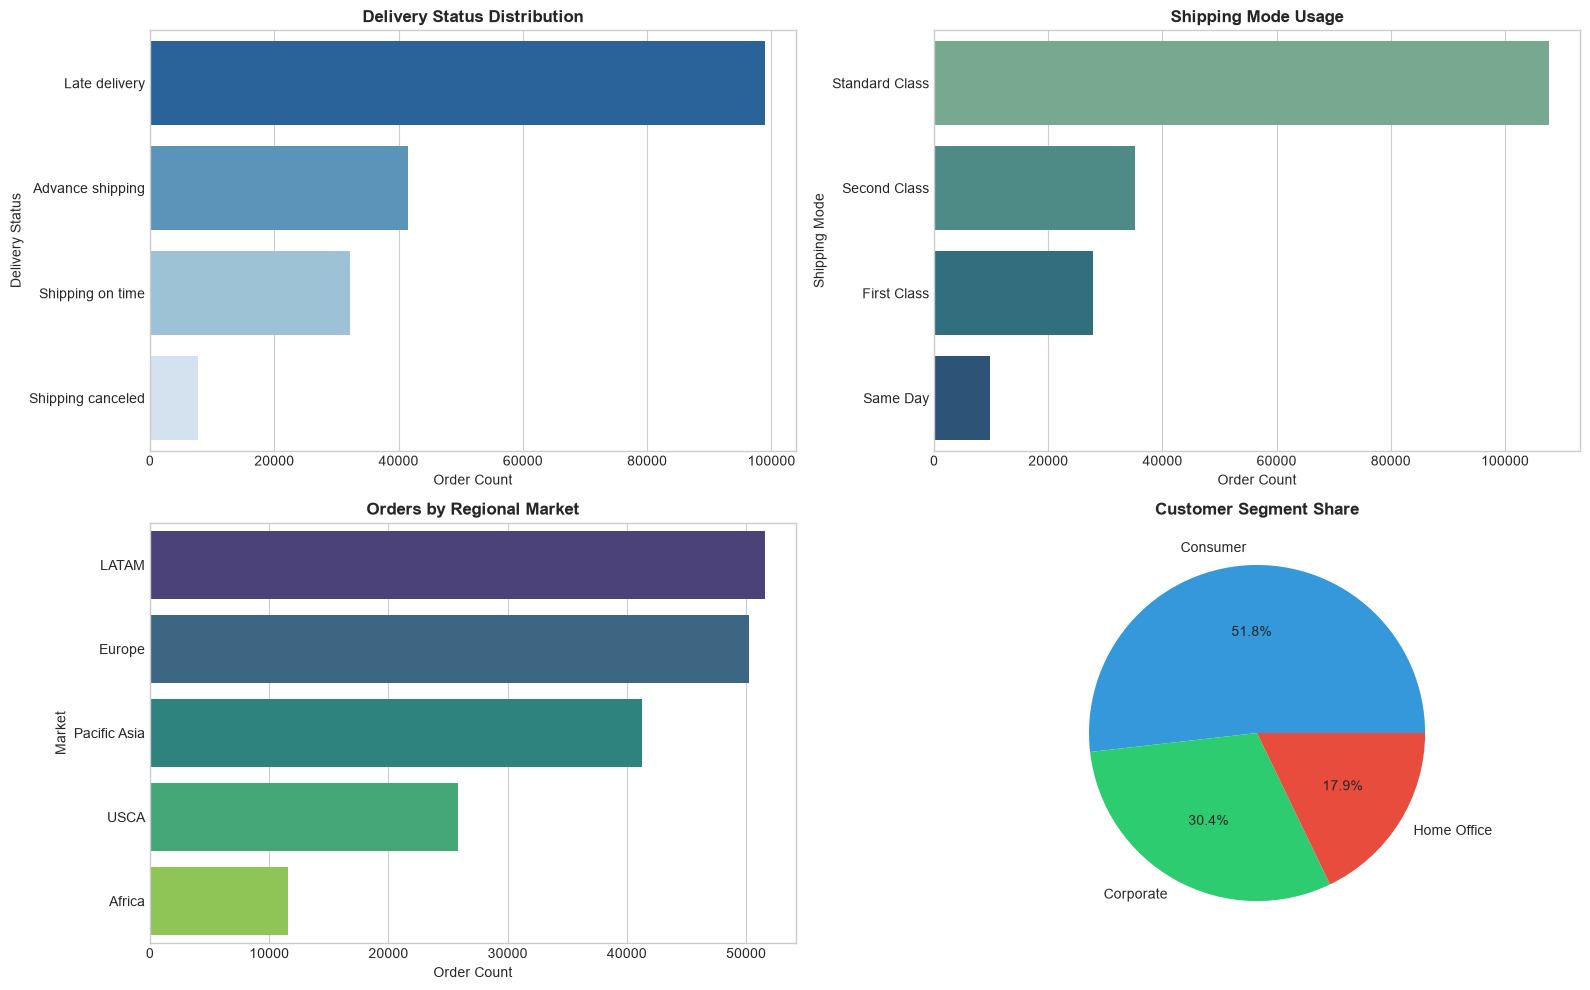

In [10]:
# Categorical Dimensions Exploration (Core Business Categories)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Delivery Status
deliv_cnt = a['Delivery Status'].value_counts()
sns.barplot(x=deliv_cnt.values, y=deliv_cnt.index, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Delivery Status Distribution", fontweight='bold')
axes[0, 0].set_xlabel("Order Count")

# 2. Shipping Mode
ship_cnt = a['Shipping Mode'].value_counts()
sns.barplot(x=ship_cnt.values, y=ship_cnt.index, ax=axes[0, 1], palette="crest")
axes[0, 1].set_title("Shipping Mode Usage", fontweight='bold')
axes[0, 1].set_xlabel("Order Count")

# 3. Market Distribution
mkt_cnt = a['Market'].value_counts()
sns.barplot(x=mkt_cnt.values, y=mkt_cnt.index, ax=axes[1, 0], palette="viridis")
axes[1, 0].set_title("Orders by Regional Market", fontweight='bold')
axes[1, 0].set_xlabel("Order Count")

# 4. Customer Segment
seg_cnt = a['Customer Segment'].value_counts()
axes[1, 1].pie(seg_cnt.values, labels=seg_cnt.index, autopct='%1.1f%%', colors=['#3498db', '#2ecc71', '#e74c3c'])
axes[1, 1].set_title("Customer Segment Share", fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Continuous Numerical Distributions & Outlier Analytics (Descriptive Stats, Skewness, IQR & Boxplots)
Here we evaluate the distribution shape, spread, skewness, and outliers using IQR bounds and statistical plots.

In [11]:
# Summary statistics, skewness, and IQR Outlier detection
continuous_features = [
    'Sales', 'Order Item Total', 'Benefit per order', 'Product Price',
    'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity',
    'Days for shipping (real)', 'Days for shipment (scheduled)'
]

stats_table = a[continuous_features].describe().T
stats_table['skewness'] = a[continuous_features].skew()
stats_table = stats_table[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']].round(2)
print("=== Descriptive Statistics & Skewness of Continuous Features ===")
display(stats_table)

# IQR Outlier summary
outlier_data = []
for col in continuous_features:
    s = a[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lb = q1 - 1.5 * iqr
    ub = q3 + 1.5 * iqr
    outliers = s[(s < lb) | (s > ub)]
    outlier_data.append({
        "Feature": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower_Bound": round(lb, 2),
        "Upper_Bound": round(ub, 2),
        "Outlier_Count": len(outliers),
        "Outlier_%": round((len(outliers) / len(s)) * 100, 2)
    })

print("=== IQR Outlier Summary Across Features ===")
display(pd.DataFrame(outlier_data).sort_values(by="Outlier_%", ascending=False))

=== Descriptive Statistics & Skewness of Continuous Features ===


,count,mean,std,min,25%,50%,75%,max,skewness
Sales,180519.00,203.77,132.27,9.99,119.98,199.92,299.95,1999.99,2.88
Order Item Total,180519.00,183.11,120.04,7.49,104.38,163.99,247.40,1939.99,2.89
Benefit per order,180519.00,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80,-4.74
Product Price,180519.00,141.23,139.73,9.99,50.00,59.99,199.99,1999.99,3.19
Order Item Discount,180519.00,20.66,21.80,0.00,5.40,14.00,29.99,500.00,3.04
Order Item Discount Rate,180519.00,0.10,0.07,0.00,0.04,0.10,0.16,0.25,0.34
Order Item Quantity,180519.00,2.13,1.45,1.00,1.00,1.00,3.00,5.00,0.88
Days for shipping (real),180519.00,3.50,1.62,0.00,2.00,3.00,5.00,6.00,0.08
Days for shipment (scheduled),180519.00,2.93,1.37,0.00,2.00,4.00,4.00,4.00,-0.73


=== IQR Outlier Summary Across Features ===


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_%
2,Benefit per order,7.00,64.80,57.80,-79.70,151.50,18942,10.49
4,Order Item Discount,5.40,29.99,24.59,-31.48,66.87,7537,4.18
3,Product Price,50.00,199.99,149.99,-174.99,424.98,2048,1.13
1,Order Item Total,104.38,247.40,143.02,-110.15,461.93,1943,1.08
0,Sales,119.98,299.95,179.97,-149.98,569.91,488,0.27
5,Order Item Discount Rate,0.04,0.16,0.12,-0.14,0.34,0,0.00
6,Order Item Quantity,1.00,3.00,2.00,-2.00,6.00,0,0.00
7,Days for shipping (real),2.00,5.00,3.00,-2.50,9.50,0,0.00
8,Days for shipment (scheduled),2.00,4.00,2.00,-1.00,7.00,0,0.00


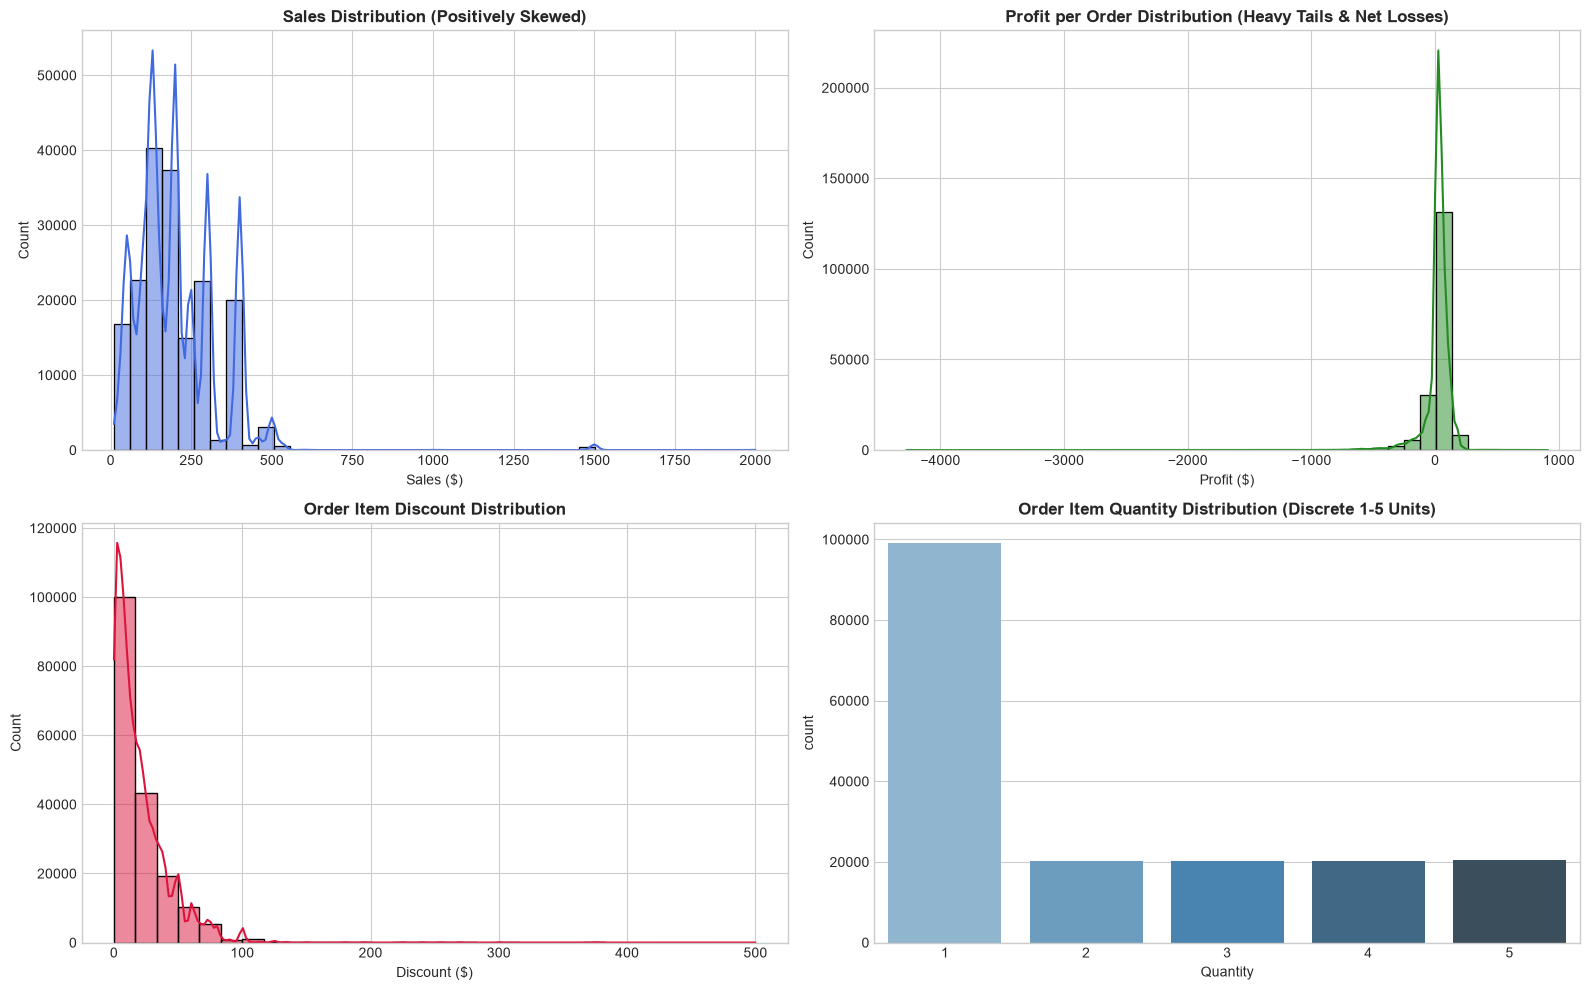

In [12]:
# Financial Distribution Histograms & KDE
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Sales
sns.histplot(a['Sales'], bins=40, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title("Sales Distribution (Positively Skewed)", fontweight='bold')
axes[0, 0].set_xlabel("Sales ($)")

# 2. Profit per order
sns.histplot(a['Benefit per order'], bins=40, kde=True, ax=axes[0, 1], color='forestgreen')
axes[0, 1].set_title("Profit per Order Distribution (Heavy Tails & Net Losses)", fontweight='bold')
axes[0, 1].set_xlabel("Profit ($)")

# 3. Order Item Discount
sns.histplot(a['Order Item Discount'], bins=30, kde=True, ax=axes[1, 0], color='crimson')
axes[1, 0].set_title("Order Item Discount Distribution", fontweight='bold')
axes[1, 0].set_xlabel("Discount ($)")

# 4. Item Quantity
sns.countplot(x=a['Order Item Quantity'], ax=axes[1, 1], palette='Blues_d')
axes[1, 1].set_title("Order Item Quantity Distribution (Discrete 1-5 Units)", fontweight='bold')
axes[1, 1].set_xlabel("Quantity")

plt.tight_layout()
plt.show()

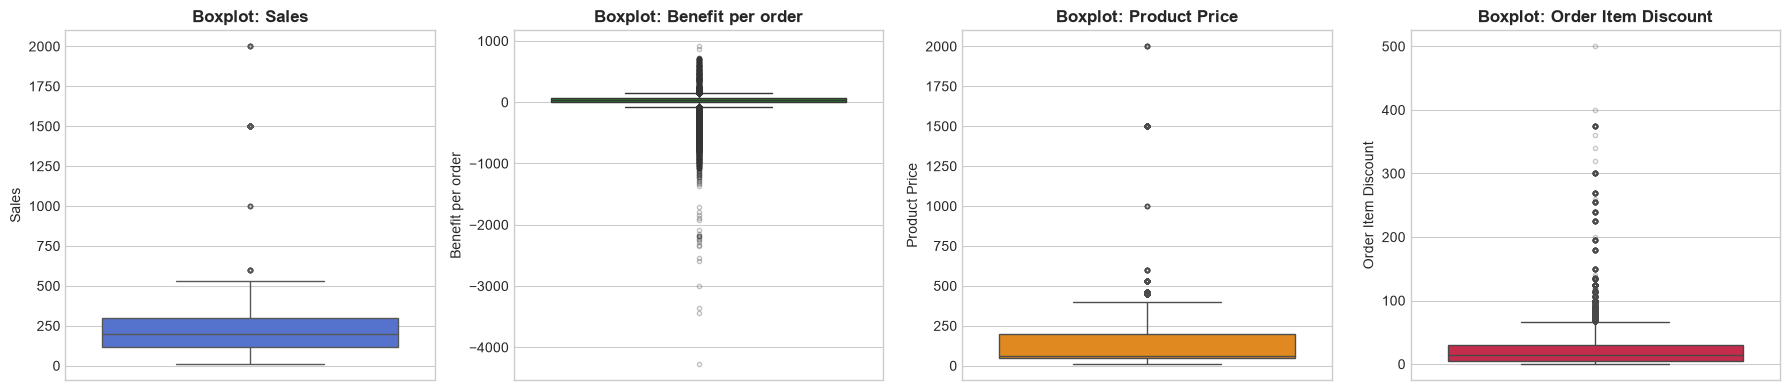

In [13]:
# Outlier Visualizations: Boxplots for Continuous Numerical Features
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
outlier_cols = ['Sales', 'Benefit per order', 'Product Price', 'Order Item Discount']
colors = ['royalblue', 'forestgreen', 'darkorange', 'crimson']

for ax, col, color in zip(axes, outlier_cols, colors):
    sns.boxplot(y=a[col], ax=ax, color=color, flierprops=dict(marker='o', markersize=3, alpha=0.3))
    ax.set_title(f"Boxplot: {col}", fontweight='bold')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

## 7. Operational Dynamics & Target Leakage Investigation

=== Target Leakage Audit: Delivery Status vs Late Delivery Risk ===


Late_delivery_risk,0,1,All
Delivery Status,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519


Finding: Delivery Status='Late delivery' perfectly maps 100% to Late_delivery_risk=1.
This represents a 100% deterministic target leakage feature that must not be used as an input in predictive models.


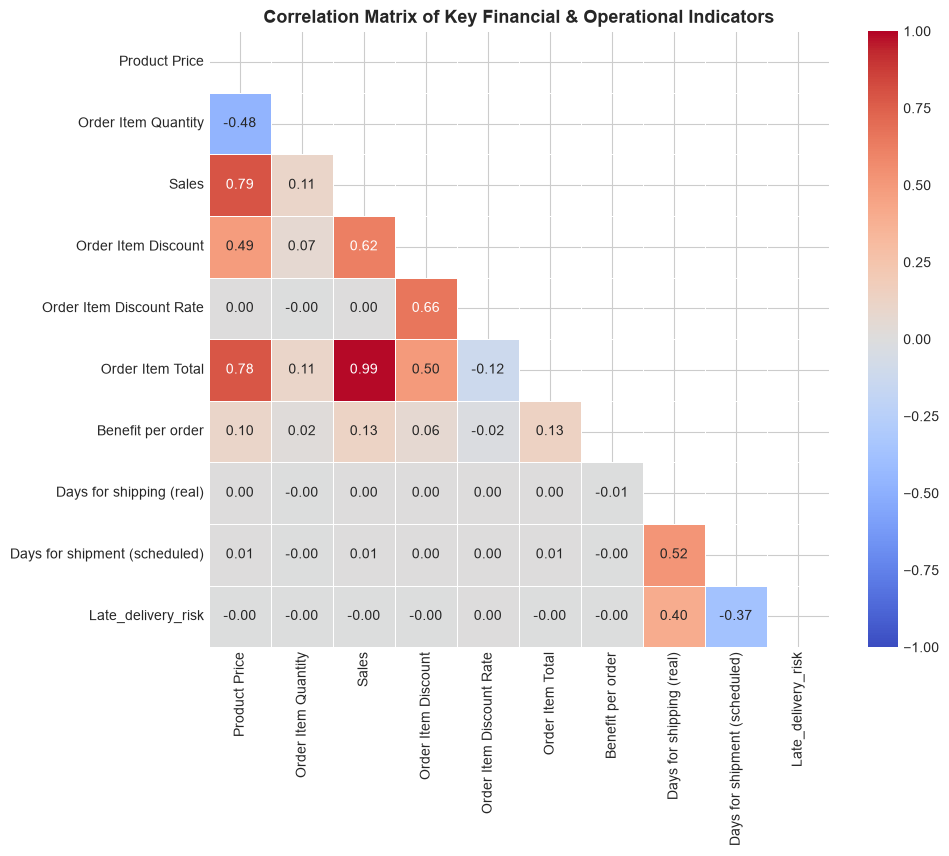

In [14]:
# Target Leakage Audit: Late Delivery Risk vs Delivery Status
print("=== Target Leakage Audit: Delivery Status vs Late Delivery Risk ===")
leakage_cross = pd.crosstab(a['Delivery Status'], a['Late_delivery_risk'], margins=True)
display(leakage_cross)
print("Finding: Delivery Status='Late delivery' perfectly maps 100% to Late_delivery_risk=1.")
print("This represents a 100% deterministic target leakage feature that must not be used as an input in predictive models.")

# Correlation Heatmap
corr_features = [
    'Product Price', 'Order Item Quantity', 'Sales', 'Order Item Discount',
    'Order Item Discount Rate', 'Order Item Total', 'Benefit per order',
    'Days for shipping (real)', 'Days for shipment (scheduled)', 'Late_delivery_risk'
]

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(a[corr_features].corr(), dtype=bool))
sns.heatmap(a[corr_features].corr(), mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Key Financial & Operational Indicators", fontsize=13, fontweight='bold')
plt.show()

## 8. Web Access Logs Analytics & Cross-Dataset Synergy

Total Server Access Logs in c: 469,977


Duplicate Log Records in c:     3,249


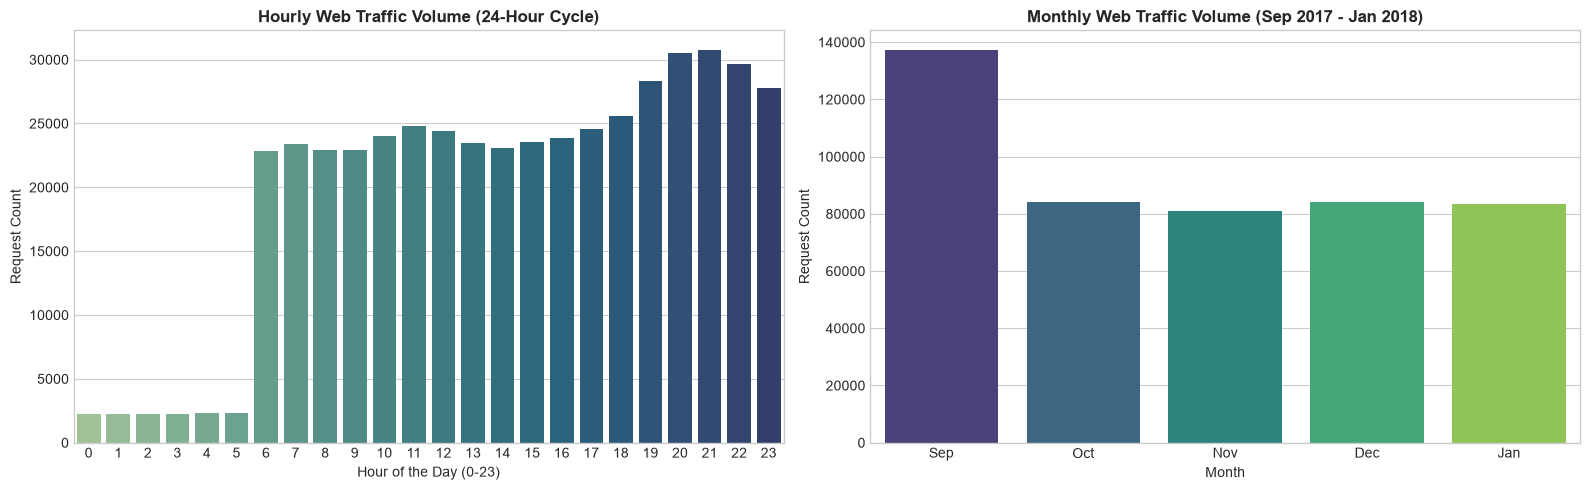

In [15]:
# Temporal Trends in E-Commerce Web Logs (Dataset c)
print(f"Total Server Access Logs in c: {len(c):,}")
print(f"Duplicate Log Records in c:     {c.duplicated().sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Hourly Distribution
hourly_traffic = c['Hour'].value_counts().sort_index()
sns.barplot(x=hourly_traffic.index, y=hourly_traffic.values, ax=axes[0], palette="crest")
axes[0].set_title("Hourly Web Traffic Volume (24-Hour Cycle)", fontweight='bold')
axes[0].set_xlabel("Hour of the Day (0-23)")
axes[0].set_ylabel("Request Count")

# Monthly Distribution
month_order = ['Sep', 'Oct', 'Nov', 'Dec', 'Jan']
monthly_traffic = c['Month'].str.strip().value_counts().reindex(month_order)
sns.barplot(x=monthly_traffic.index, y=monthly_traffic.values, ax=axes[1], palette="viridis")
axes[1].set_title("Monthly Web Traffic Volume (Sep 2017 - Jan 2018)", fontweight='bold')
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Request Count")

plt.tight_layout()
plt.show()

In [16]:
# Anomaly & Web Crawler / Bot Detection
ip_activity = c['ip'].value_counts()
bot_threshold = ip_activity.quantile(0.995)
suspected_bots = ip_activity[ip_activity > bot_threshold]

print("=== Top 8 Most Active IP Addresses (Bot / Web Scraper Suspects) ===")
print(ip_activity.head(8).to_string())
print(f"\nSuspected Bot IPs (> {bot_threshold:.0f} hits): {len(suspected_bots)} addresses accounting for {suspected_bots.sum():,} requests ({suspected_bots.sum()/len(c)*100:.1f}% of total web traffic).")

=== Top 8 Most Active IP Addresses (Bot / Web Scraper Suspects) ===
ip
157.21.93.193     566
138.21.216.113    557
77.137.114.147    516
47.102.94.70      514
83.234.215.133    514
150.89.112.119    508
211.122.14.29     505
99.237.181.177    502

Suspected Bot IPs (> 478 hits): 16 addresses accounting for 8,073 requests (1.7% of total web traffic).


Overlapping Products between Web Logs and Supply Chain Orders: 72 products


=== Top 10 Most Viewed Products vs Sales & Conversion Index ===


,Units_Sold,Total_Sales,Total_Profit,Web_Views,Cart_Adds,Cart_Add_Rate_%,Conversion_Index
Perfect Fitness Perfect Rip Deck,73698,4421143.14,493828.30,27663,7604,27.49,2.66
Nike Men's Dri-FIT Victory Golf Polo,62956,3147800.00,350421.03,25424,7240,28.48,2.48
Nike Men's CJ Elite 2 TD Football Cleat,22246,2891757.66,311902.82,25020,7265,29.04,0.89
O'Brien Men's Neoprene Life Vest,57803,2888993.91,318451.43,16073,4581,28.50,3.60
Pelican Sunstream 100 Kayak,15500,3099845.09,324076.37,16047,4594,28.63,0.97
Diamondback Women's Serene Classic Comfort Bi,13729,4118425.57,427455.57,15417,4235,27.47,0.89
Field & Stream Sportsman 16 Gun Fire Safe,17325,6929653.69,756220.77,15060,4457,29.59,1.15
Under Armour Hustle Storm Medium Duffle Bag,846,29601.54,4067.61,13670,3835,28.05,0.06
Columbia Men's PFG Anchor Tough T-Shirt,928,27840.00,2454.80,13628,3784,27.77,0.07
Nike Men's Free 5.0+ Running Shoe,36680,3667633.20,379915.82,13518,3674,27.18,2.71


,Web_Views_%,Sales_Revenue_%
Outdoors,17.02,3.41
Apparel,16.86,21.68
Footwear,16.84,10.89
Fan Shop,16.74,46.52
Fitness,16.28,1.08
Golf,16.26,12.53


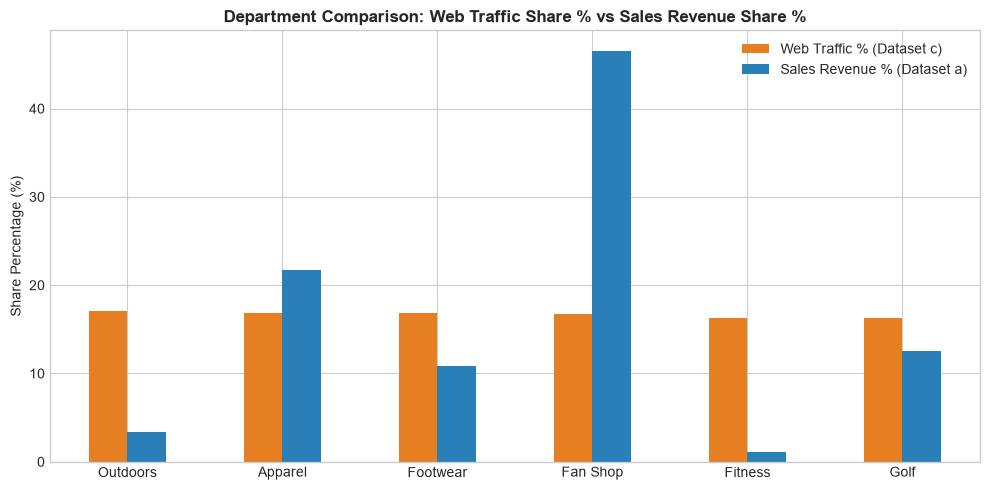

In [17]:
# Cross-Dataset Funnel: Web Traffic Engagement vs Supply Chain Sales
overlap_products = set(c['Product'].str.strip()).intersection(set(a['Product Name'].str.strip()))
print(f"Overlapping Products between Web Logs and Supply Chain Orders: {len(overlap_products)} products")

c_dedup = c.drop_duplicates()
web_views = c_dedup['Product'].str.strip().value_counts().rename("Web_Views")
cart_adds = c_dedup[c_dedup['url'].str.contains('add_to_cart')]['Product'].str.strip().value_counts().rename("Cart_Adds")

sales_agg = a.groupby('Product Name').agg(
    Units_Sold=('Order Item Quantity', 'sum'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Benefit per order', 'sum')
)

funnel = sales_agg.join([web_views, cart_adds], how='inner').fillna(0)
funnel['Cart_Add_Rate_%'] = ((funnel['Cart_Adds'] / funnel['Web_Views']) * 100).round(2)
funnel['Conversion_Index'] = (funnel['Units_Sold'] / funnel['Web_Views']).round(3)

print("=== Top 10 Most Viewed Products vs Sales & Conversion Index ===")
display(funnel.sort_values(by="Web_Views", ascending=False).head(10))

# Department-level Comparison: Web Traffic Share % vs Sales Revenue Share %
c_dept = (c_dedup['Department'].str.strip().str.title().value_counts(normalize=True) * 100).rename("Web_Views_%")
a_dept = (a.groupby('Department Name')['Sales'].sum() / a['Sales'].sum() * 100).rename("Sales_Revenue_%")

dept_comparison = pd.concat([c_dept, a_dept], axis=1).dropna().round(2)
display(dept_comparison)

dept_comparison.plot(kind='bar', figsize=(10, 5), color=['#e67e22', '#2980b9'])
plt.title("Department Comparison: Web Traffic Share % vs Sales Revenue Share %", fontweight='bold')
plt.ylabel("Share Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Web Traffic % (Dataset c)", "Sales Revenue % (Dataset a)"])
plt.tight_layout()
plt.show()

## 9. Summary of Phase 1 Data Understanding & EDA Takeaways:
1. **Preservation of Raw Structure:** All 53 columns in `a`, 2 fields in `b`, and 8 features in `c` were audited in their complete original form without removal or deletion.
2. **Transaction Grain Confirmed:** Verified that the analytical grain is at the `Order Item` level (`Order Item Id` is a 100% unique primary key).
3. **Data Quality Profile:**
   - Identified 100% missing `Product Description` and 86.2% missing `Order Zipcode` (systematic missingness outside US).
   - Uncovered the column shift in customer state/zipcode for Elk Grove and El Monte.
   - Diagnosed 100% duplicate pairs (`Order Customer Id`, `Order Profit Per Order`, `Sales per customer`, `Product Category Id`, `Order Item Product Price`, `Order Item Cardprod Id`) and constant `Product Status` (all 0s).
4. **Statistical & Distributional Foundations:**
   - Financial indicators exhibit strong positive skewness with authentic bulk order outliers and legitimate net operating losses.
   - Overall late delivery rate is 54.8%, with `Delivery Status` confirmed as a deterministic target leakage variable.
5. **Readiness for Phase 2:** With the data thoroughly understood, audited, and visually explored, all findings are documented to guide the downstream preprocessing, cleaning, feature engineering, and predictive modeling in Phase 2.